# TP2 — Ejercicio 3.4: completado de knowledge graph con PairRE

**Bases de Datos Orientadas a Grafos** · UCA · 2.º cuatrimestre 2026 · Docente: José Canelón
**Trabajo 2 — eje Drama** · Matías Adell, Agustín Giannice, Facundo Mazzola

Consigna 3.4: *en el notebook de Python, resolver el completado de knowledge graph con PairRE. Entregable: las métricas (MRR, Hits@10) y 3 hechos propuestos que no estaban en el grafo.*

Pasos del notebook:

1. Se extraen del grafo de películas las **tripletas estructurales** `IN_GENRE` y `ACTED_IN` de las películas con **al menos 20 calificaciones** (el corte de factibilidad de las NOTAS). Se cachean en `outputs/kg/triples.tsv`.
2. Se hace un split 80/10/10 con semilla 42.
3. Se entrena **PairRE** con PyKEEN: `f(h,t) = -‖h∘r_H − t∘r_T‖`, que modela mejor las relaciones 1-N, N-1 y N-N que TransE.
4. Se informan **MRR** y **Hits@10** sobre test, en el escenario filtrado.
5. Se proponen 3 hechos nuevos en el eje del grupo: las películas que hoy **no** son Drama con mayor score para `(película, IN_GENRE, Drama)`.

Corre entero en CPU. Neo4j solo hace falta la primera vez, para generar el TSV; después el notebook lee del caché, así que PyKEEN puede entrenar con Neo4j apagado (NOTAS: no correr todo a la vez).

## 0. Entorno y semillas

In [1]:
# Entorno: env conda 'grafos-tp2' (ver environment.yml en la raíz). Instalación de referencia:
# !pip install pykeen neo4j pandas matplotlib
import json
import random
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import pykeen

# Avisos irrelevantes en CPU (pin_memory, barras de progreso de Jupyter)
warnings.filterwarnings('ignore', message='.*pin_memory.*')
warnings.filterwarnings('ignore', category=UserWarning, module='tqdm')
warnings.filterwarnings('ignore', message='.*IProgress.*')

SEED = 42  # indicación de la cátedra: semilla 42 en todo lo que la acepte
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Raíz del proyecto (donde está CONSIGNA.md), para encontrar outputs/ y src/
RAIZ = Path.cwd().resolve()
while not (RAIZ / 'CONSIGNA.md').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

SALIDA = RAIZ / 'outputs' / 'kg'
SALIDA.mkdir(parents=True, exist_ok=True)
TSV = SALIDA / 'triples.tsv'

print('PyKEEN', pykeen.get_version(), '| torch', torch.__version__, '| CUDA disponible:', torch.cuda.is_available())

PyKEEN 1.11.1 | torch 2.15.0+cpu | CUDA disponible: False


## 1. Tripletas desde Neo4j (con caché)

Para cada película con al menos 20 calificaciones se toman:

- `(película) -[IN_GENRE]-> (género)`
- `(persona) -[ACTED_IN]-> (película)`

**Identificadores de entidad.** En el grafo hay 210 títulos y 32 nombres de persona repetidos, así que se usan etiquetas legibles y únicas:

- películas: `Título (año)`, más `[movieId]` solo si dos películas de la muestra coinciden;
- personas: `Nombre`, más `[tmdbId]` solo si el nombre se repite;
- géneros: su nombre.

In [2]:
CONSULTA = '''
MATCH (m:Movie)
WHERE COUNT { (m)<-[:RATED]-(:User) } >= 20
CALL (m) {
  MATCH (m)-[:IN_GENRE]->(g:Genre)
  RETURN 'IN_GENRE' AS relacion, g.name AS nombreOtro, g.name AS idOtro
  UNION ALL
  MATCH (p:Person)-[:ACTED_IN]->(m)
  RETURN 'ACTED_IN' AS relacion, p.name AS nombreOtro, p.tmdbId AS idOtro
}
RETURN m.movieId AS movieId, m.title AS titulo, m.year AS anio, relacion, nombreOtro, idOtro
'''


def extraer_de_neo4j() -> pd.DataFrame:
    from src.tp2.conexion import obtener_driver  # lee la contraseña de .env (no se imprime)
    driver, base = obtener_driver()
    try:
        registros, _, _ = driver.execute_query(CONSULTA, database_=base)
    finally:
        driver.close()
    crudo = pd.DataFrame([r.data() for r in registros])

    # Etiqueta única de película
    crudo['etiquetaPeli'] = crudo['titulo'] + ' (' + crudo['anio'].map(lambda a: 's/f' if pd.isna(a) else str(int(a))) + ')'
    pelis = crudo[['movieId', 'etiquetaPeli']].drop_duplicates()
    repetidas = pelis['etiquetaPeli'].duplicated(keep=False)
    pelis.loc[repetidas, 'etiquetaPeli'] = pelis.loc[repetidas, 'etiquetaPeli'] + ' [' + pelis.loc[repetidas, 'movieId'] + ']'
    crudo = crudo.drop(columns='etiquetaPeli').merge(pelis, on='movieId')

    # Etiqueta única de persona
    actores = crudo[crudo.relacion == 'ACTED_IN'][['nombreOtro', 'idOtro']].drop_duplicates()
    nombre_repetido = actores['nombreOtro'].duplicated(keep=False)
    actores['etiquetaPersona'] = actores['nombreOtro']
    actores.loc[nombre_repetido, 'etiquetaPersona'] = actores.loc[nombre_repetido, 'nombreOtro'] + ' [' + actores.loc[nombre_repetido, 'idOtro'].astype(str) + ']'
    crudo = crudo.merge(actores, on=['nombreOtro', 'idOtro'], how='left')

    genero = crudo[crudo.relacion == 'IN_GENRE']
    actuo = crudo[crudo.relacion == 'ACTED_IN']
    triples = pd.concat([
        pd.DataFrame({'cabeza': genero.etiquetaPeli, 'relacion': 'IN_GENRE', 'cola': genero.nombreOtro}),
        pd.DataFrame({'cabeza': actuo.etiquetaPersona, 'relacion': 'ACTED_IN', 'cola': actuo.etiquetaPeli}),
    ]).drop_duplicates().sort_values(['relacion', 'cabeza', 'cola']).reset_index(drop=True)

    # Control: ninguna etiqueta puede nombrar a dos tipos de entidad distintos
    pelis_set = set(pelis.etiquetaPeli)
    assert not (pelis_set & set(actores.etiquetaPersona)), 'colisión película/persona'
    assert not (pelis_set & set(genero.nombreOtro)), 'colisión película/género'
    return triples


if TSV.exists():
    triples = pd.read_csv(TSV, sep='\t', dtype=str, keep_default_na=False)
    print(f'Tripletas leídas del caché: {TSV.relative_to(RAIZ)}')
else:
    triples = extraer_de_neo4j()
    triples.to_csv(TSV, sep='\t', index=False)
    print(f'Tripletas extraídas de Neo4j y guardadas en {TSV.relative_to(RAIZ)}')

peliculas = set(triples.loc[triples.relacion == 'IN_GENRE', 'cabeza'])
print('Tripletas por relación:')
print(triples.relacion.value_counts().to_string())
print(f'Total: {len(triples)} tripletas | películas: {len(peliculas)} | '
      f'entidades: {len(set(triples.cabeza) | set(triples.cola))}')
triples.head()

Tripletas leídas del caché: outputs\kg\triples.tsv
Tripletas por relación:
relacion
ACTED_IN    5203
IN_GENRE    3516
Total: 8719 tripletas | películas: 1303 | entidades: 4052


,cabeza,relacion,cola
0,Aaron Eckhart,ACTED_IN,"Dark Knight, The (2008)"
1,Aaron Eckhart,ACTED_IN,Erin Brockovich (2000)
2,Aaron Eckhart,ACTED_IN,Thank You for Smoking (2005)
3,Aaron Ruell,ACTED_IN,Napoleon Dynamite (2004)
4,Aaron Taylor-Johnson,ACTED_IN,Kick-Ass (2010)


## 2. Split entrenamiento / validación / test (80/10/10, semilla 42)

In [3]:
from pykeen.triples import TriplesFactory

tf = TriplesFactory.from_labeled_triples(triples[['cabeza', 'relacion', 'cola']].values)
entrenamiento, validacion, prueba = tf.split([0.8, 0.1, 0.1], random_state=SEED)
print('Completo     :', tf)
print('Entrenamiento:', entrenamiento)
print('Validación   :', validacion)
print('Test         :', prueba)

Completo     : TriplesFactory(num_entities=4052, num_relations=2, create_inverse_triples=False, num_triples=8719)
Entrenamiento: TriplesFactory(num_entities=4052, num_relations=2, create_inverse_triples=False, num_triples=6975)
Validación   : TriplesFactory(num_entities=4052, num_relations=2, create_inverse_triples=False, num_triples=872)
Test         : TriplesFactory(num_entities=4052, num_relations=2, create_inverse_triples=False, num_triples=872)


## 3. Entrenamiento de PairRE

Configuración: dimensión 128 (la moderada de las NOTAS), 100 épocas, semilla 42 y CPU. La evaluación es *filtrada*: al rankear cada tripleta de test se descartan las otras tripletas verdaderas de entrenamiento y validación.

INFO:pykeen.evaluation.evaluator:Evaluation took 3.86s seconds


Entrenamiento: 100 épocas | pérdida final: 0.0210


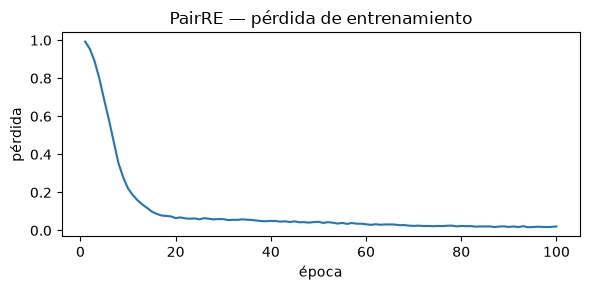

In [4]:
from pykeen.pipeline import pipeline

resultado = pipeline(
    training=entrenamiento,
    validation=validacion,
    testing=prueba,
    model='PairRE',
    model_kwargs=dict(embedding_dim=128),
    training_kwargs=dict(num_epochs=100, use_tqdm=False),
    evaluation_kwargs=dict(use_tqdm=False),
    random_seed=SEED,
    device='cpu',
)
print(f'Entrenamiento: {len(resultado.losses)} épocas | pérdida final: {resultado.losses[-1]:.4f}')

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, len(resultado.losses) + 1), resultado.losses)
ax.set_xlabel('época'); ax.set_ylabel('pérdida'); ax.set_title('PairRE — pérdida de entrenamiento')
fig.tight_layout()
fig.savefig(SALIDA / 'pairre_perdida.png', dpi=150)
plt.show()

## 4. Métricas en test: MRR y Hits@10

In [5]:
metricas = {
    'modelo': 'PairRE',
    'mrr': float(resultado.get_metric('mrr')),
    'hits_at_10': float(resultado.get_metric('hits@10')),
    'hits_at_1': float(resultado.get_metric('hits@1')),
    'hits_at_3': float(resultado.get_metric('hits@3')),
    'escenario': 'filtrado, ambos lados (head y tail), rank realista',
    'tripletas': {'total': int(tf.num_triples), 'entrenamiento': int(entrenamiento.num_triples),
                  'validacion': int(validacion.num_triples), 'test': int(prueba.num_triples)},
    'entidades': int(tf.num_entities),
    'relaciones': int(tf.num_relations),
    'config': {'embedding_dim': 128, 'num_epochs': 100, 'random_seed': SEED, 'split': [0.8, 0.1, 0.1]},
}
(SALIDA / 'pairre_metricas.json').write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding='utf-8')
print(f"MRR     : {metricas['mrr']:.4f}")
print(f"Hits@10 : {metricas['hits_at_10']:.4f}")
print(f"(Hits@1 : {metricas['hits_at_1']:.4f} | Hits@3: {metricas['hits_at_3']:.4f})")

MRR     : 0.1046
Hits@10 : 0.1921
(Hits@1 : 0.0596 | Hits@3: 0.1175)


## 5. Hechos propuestos: películas que deberían ser Drama

Para la consulta `(?, IN_GENRE, Drama)` se rankean todas las cabezas posibles con el modelo entrenado. Se filtra a las entidades que son películas y se descartan las que ya tienen el género Drama en el grafo: la muestra trae **todas** las `IN_GENRE` de cada película, así que estar fuera del TSV equivale a no estar en el grafo. Las 3 de mayor score son los hechos propuestos.

In [6]:
from pykeen.predict import predict_target

pred = predict_target(model=resultado.model, relation='IN_GENRE', tail='Drama',
                      triples_factory=resultado.training)
ranking = pred.df.sort_values('score', ascending=False).reset_index(drop=True)

ya_drama = set(triples.loc[(triples.relacion == 'IN_GENRE') & (triples.cola == 'Drama'), 'cabeza'])
candidatas = ranking[ranking.head_label.isin(peliculas) & ~ranking.head_label.isin(ya_drama)].copy()
generos_actuales = (triples[triples.relacion == 'IN_GENRE'].groupby('cabeza')['cola']
                    .apply(lambda g: ', '.join(sorted(g))))

hechos = candidatas.head(3).assign(
    relacion='IN_GENRE', genero='Drama',
    generos_actuales=lambda d: d.head_label.map(generos_actuales),
    puesto_entre_no_drama=range(1, 4),
).rename(columns={'head_label': 'pelicula'})[['puesto_entre_no_drama', 'pelicula', 'relacion', 'genero', 'score', 'generos_actuales']]
hechos.to_csv(SALIDA / 'hechos_propuestos.csv', index=False)
print(f'Películas de la muestra que ya son Drama: {len(ya_drama)} de {len(peliculas)}')
hechos

Películas de la muestra que ya son Drama: 605 de 1303


,puesto_entre_no_drama,pelicula,relacion,genero,score,generos_actuales
332,1,Vanilla Sky (2001),IN_GENRE,Drama,-2.568820,"Mystery, Romance, Sci-Fi, Thriller"
345,2,"African Queen, The (1951)",IN_GENRE,Drama,-2.592372,"Adventure, Comedy, Romance, War"
357,3,Devil in a Blue Dress (1995),IN_GENRE,Drama,-2.608653,"Crime, Film-Noir, Mystery, Thriller"


In [7]:
# Verificación opcional contra Neo4j: las 3 películas propuestas NO tienen hoy el género Drama.
# Si Neo4j está apagado (por ejemplo, para entrenar según las NOTAS), la celda lo avisa y sigue.
try:
    from src.tp2.conexion import obtener_driver
    driver, base = obtener_driver()
    verificacion = []
    for etiqueta in hechos.pelicula:
        titulo, resto = etiqueta.rsplit(' (', 1)
        anio = resto.split(')')[0]
        filas, _, _ = driver.execute_query(
            '''MATCH (m:Movie {title: $titulo}) WHERE toString(m.year) = $anio
               RETURN m.title AS titulo, m.year AS anio,
                      EXISTS { (m)-[:IN_GENRE]->(:Genre {name: 'Drama'}) } AS yaEsDrama,
                      [(m)-[:IN_GENRE]->(g) | g.name] AS generos''',
            titulo=titulo, anio=anio, database_=base)
        verificacion += [f.data() for f in filas]
    driver.close()
    display(pd.DataFrame(verificacion))
except Exception as exc:
    print('Verificación contra Neo4j omitida:', type(exc).__name__, exc)

,titulo,anio,yaEsDrama,generos
0,Vanilla Sky,2001,False,"[Thriller, Romance, Sci-Fi, Mystery]"
1,"African Queen, The",1951,False,"[War, Romance, Comedy, Adventure]"
2,Devil in a Blue Dress,1995,False,"[Mystery, Film-Noir, Thriller, Crime]"


## Interpretación

- **Métricas.** MRR ≈ 0,105 y Hits@10 ≈ 0,19: para una tripleta de test, la entidad correcta queda entre las 10 primeras de 4.052 candidatas en casi 1 de cada 5 casos. Un ranking al azar daría Hits@10 ≈ 10/4.052 ≈ 0,0025, así que el modelo es unas 75 veces mejor. El valor es mucho más bajo que en el dataset *Nations* de la práctica (MRR ≈ 0,73) porque este KG es **ralo**: 8.719 tripletas para 4.052 entidades (≈2,2 por entidad) y la mayoría de los actores aparece en una o dos tripletas, así que su embedding se aprende con muy poca señal. La pérdida converge hacia la época 20.
- **Hechos propuestos.** Las tres películas mejor puntuadas para `(?, IN_GENRE, Drama)` que hoy no tienen ese género son plausibles: *Vanilla Sky* (2001) suele describirse como drama psicológico, *The African Queen* (1951) como aventura y romance con mucho de drama, y *Devil in a Blue Dress* (1995) como drama criminal neo-noir. El score de PairRE es una distancia con signo negativo (más alto = más plausible). PairRE ubica estas películas cerca de las de Drama porque comparten actores y géneros vecinos (Mystery, Romance, Crime, War) con muchas películas dramáticas del grafo.